In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [2]:
# read all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [5]:
# build vocabulary of the characters and the mapping to/from integer
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [117]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [32]:
C = torch.randn((27,2))

In [72]:
X.shape ,X.dtype,Y.shape ,Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [34]:
C[X].shape

torch.Size([32, 3, 2])

In [23]:
X[13,2]

tensor(1)

In [35]:
C[X][13,2]

tensor([-0.3841,  1.7827])

In [25]:
C[1]

tensor([-1.1413,  0.3508])

In [36]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [37]:
W1 = torch.randn((6,100))
b1 = torch.randn(100)

In [38]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

In [41]:
h

tensor([[ 0.9924,  0.7052, -0.9830,  ..., -0.9776,  0.1089,  0.9899],
        [ 0.6133, -0.9025, -0.9986,  ...,  0.7043, -0.9867, -0.9984],
        [ 0.9993, -0.9973, -0.9340,  ...,  0.2299, -0.9834, -0.9976],
        ...,
        [-0.9979, -0.9819,  0.9695,  ...,  1.0000, -0.9944, -0.9998],
        [ 0.7547, -0.9943,  0.9794,  ..., -0.9416, -0.9999, -0.9997],
        [ 0.9928,  0.9990, -0.3170,  ...,  0.9999,  0.9339,  1.0000]])

In [40]:
h.shape

torch.Size([32, 100])

In [42]:
W2 = torch.randn((100,27))
b2 = torch.randn(27)

In [43]:
logits = h @ W2 + b2

In [44]:
logits.shape

torch.Size([32, 27])

In [45]:
counts = logits.exp()

In [47]:
prob = counts / counts.sum(1, keepdims=True)
prob

tensor([[6.8862e-04, 8.0359e-03, 1.5242e-04, 4.8256e-03, 6.6511e-02, 8.8868e-01,
         3.7691e-03, 1.4526e-13, 1.1060e-06, 1.1003e-02, 5.3986e-10, 3.2608e-10,
         4.5323e-07, 4.1146e-03, 6.6594e-04, 1.2718e-05, 1.2024e-09, 1.4957e-05,
         2.9735e-07, 9.9891e-09, 1.4222e-07, 1.3629e-08, 8.0178e-09, 2.1537e-04,
         1.1267e-02, 4.1846e-05, 2.6226e-06],
        [3.5962e-04, 4.1062e-15, 4.4276e-08, 2.4726e-04, 4.9370e-06, 1.6022e-07,
         1.6145e-06, 6.5497e-16, 5.7506e-07, 2.2576e-09, 2.1666e-15, 9.9041e-01,
         3.8739e-06, 1.0962e-04, 4.0827e-03, 1.4079e-04, 3.7718e-07, 6.4796e-11,
         1.0193e-08, 1.1432e-10, 4.5070e-12, 1.3244e-10, 1.1743e-03, 3.4598e-03,
         1.2984e-07, 1.7888e-08, 2.6998e-07],
        [3.9590e-09, 6.0817e-10, 1.8836e-05, 9.2773e-01, 1.5004e-12, 3.3800e-03,
         3.7099e-09, 2.9546e-12, 9.8724e-09, 1.4228e-02, 8.6069e-19, 2.7309e-04,
         5.6260e-03, 5.0931e-12, 8.3776e-04, 1.7783e-05, 8.8287e-08, 4.3803e-06,
         2.4007e-

In [48]:
prob.shape

torch.Size([32, 27])

In [49]:
torch.arange(32)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [50]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [51]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(16.8381)

In [52]:
# ------------ now made respectable :) ---------------

In [118]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [145]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [146]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [147]:
emb = C[X]                                       # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)        # (32, 100)
logits = h @ W2 + b2                             # (32, 27)
# counts = logits.exp()
# prob = counts / counts.sum(1, keepdims=True)
# loss = -prob[torch.arange(32), Y].log().mean()            --> this all  3 lines equals to below 1 single line of cross_entropy
F.cross_entropy(logits, Y)
loss

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1140730x6 and 30x200)

In [148]:
for p in parameters:
    p.requires_grad = True

In [149]:
lre = torch.linspace(-3, 0, 1000)                   # learning rate exponent
lrs = 10**lre

In [150]:
lri = []
lossi = []
stepi = []


In [152]:
# for _ in range(10):
for i in range(50000):
    
    # mini-batch construct
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]]                         # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)         # (32, 100)
    logits = h @ W2 + b2                              # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix])
    # print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # # update
    # lr = lrs[i]
    lr = 0.1
    for p in parameters:
        p.data += -lr * p.grad

    # # track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())

print(loss.item())

2.002368211746216


In [154]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.3409, grad_fn=<NllLossBackward0>)

In [155]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.3119, grad_fn=<NllLossBackward0>)

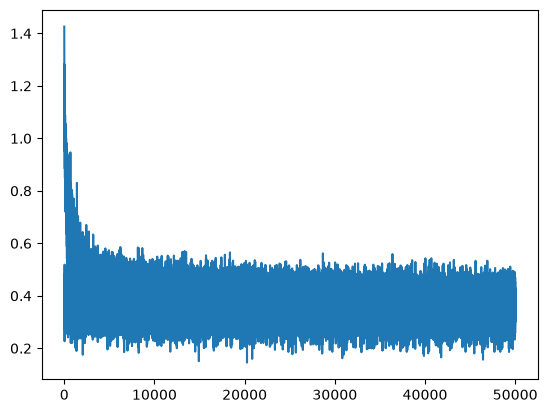

In [153]:
plt.plot(stepi, lossi)

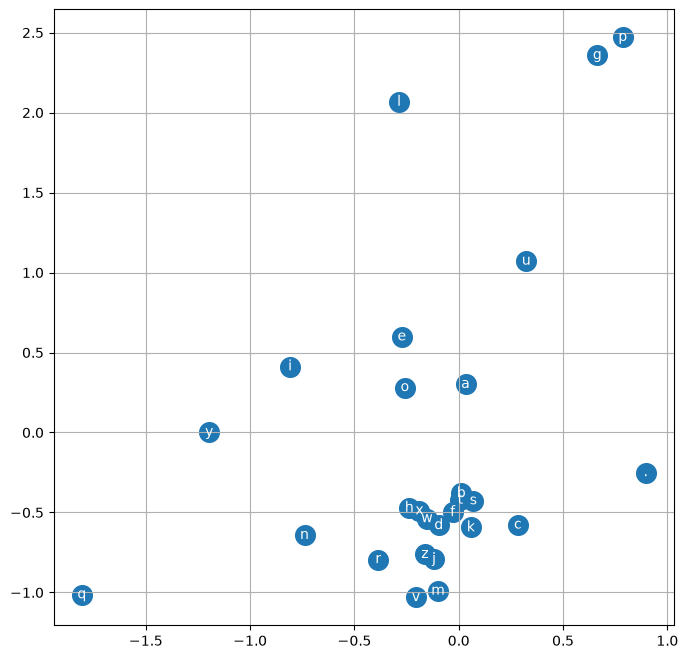

In [142]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

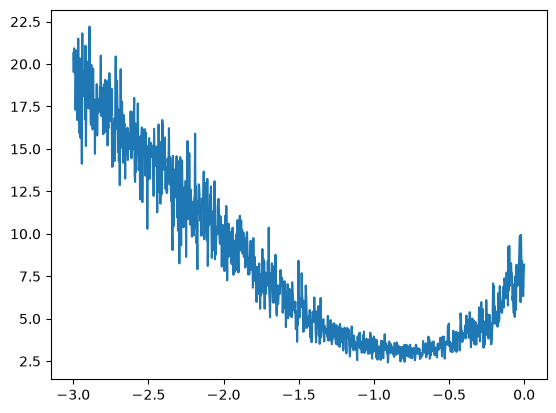

In [109]:
plt.plot(lri, lossi)                    # lri = X axis , lossi = Y-axis

In [156]:
# training split, dev/validation split, test split
# 80%, 10%, 10%

In [158]:
context = [0] * block_size
C[torch.tensor([context])].shape


torch.Size([1, 3, 10])

In [159]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carmah.
aar.
havi.
kimyloren.
cassley.
kenlynn.
nay.
dayst.
aashi.
ner.
ara.
chaily.
asleigh.
ham.
joce.
quinn.
salin.
alyanni.
wane.
osviaryn.
